Autor:
Camilo — Yachay Tech University

**Actividad:** Preprocesamiento de Datos y Clasificación con $k$-NN y Random Forest
(basada en el notebook guía *IRIS Classification with $k$-NN*, Manuel Eugenio Morocho Cayamcela, PhD)

# Clasificación del Sector de Establecimientos de Salud del Ecuador con $k$-NN
## Base de datos: Registro Estadístico de Recursos y Actividades de Salud (RAS) 2019 — INEC

## 1. Origen de la base de datos *(10%)*

La base de datos utilizada es el **Registro Estadístico de Recursos y Actividades de Salud (RAS) 2019**,
publicado por el **Instituto Nacional de Estadística y Censos del Ecuador (INEC)**.

- **Fuente oficial:** Instituto Nacional de Estadística y Censos (INEC), Ecuador — https://www.ecuadorencifras.gob.ec
- **Unidad de observación:** cada fila representa un **establecimiento de salud** (hospital, centro de salud,
  clínica, dispensario, puesto de salud, etc.) registrado en el país durante 2019.
- **Tamaño:** el archivo `inec_ras_2019.csv` contiene **4148 establecimientos** y **1913 variables**
  (separador `;`), la gran mayoría de ellas son códigos de la encuesta (`k1`, `k2`, ..., `k1424`) que
  registran recursos físicos, humanos y actividades de cada establecimiento (camas, personal, consultas,
  cirugías, equipamiento, etc.).
- **Variables de identificación/clasificación** (las que se usarán en esta actividad porque están limpias,
  documentadas y sin datos faltantes):
  - `prov_ubi`, `cant_ubi`, `parr_ubi`: provincia, cantón y parroquia donde se ubica el establecimiento.
  - `region`: región natural (Costa, Sierra, Amazónica, Insular).
  - `area`: área urbana o rural.
  - `clase`: tipo/clase de establecimiento (Centro de Salud A, Hospital Básico, Puesto de Salud, etc.).
  - `tipo`: tipología general del establecimiento.
  - `entidad`: entidad administradora (Ministerio de Salud, Seguro Social Campesino, privados, etc.).
  - `sector`: **sector al que pertenece el establecimiento** — Sector público, Privados con fines de lucro,
    Privados sin fines de lucro.

**Tarea de clasificación propuesta:** predecir el **`sector`** (público / privado con fines de lucro /
privado sin fines de lucro) de un establecimiento de salud a partir de su ubicación geográfica y del
tipo de establecimiento (`region`, `area`, `prov_ubi`, `clase`, `tipo`). Esta es una tarea realista: dado
un nuevo establecimiento del que solo conocemos dónde está y qué tipo de unidad es, ¿podemos inferir a qué
sector pertenece?

Nótese que **deliberadamente excluimos `entidad`** de las variables predictoras: esa columna casi determina
el `sector` por construcción (p. ej. "Ministerio de Salud Pública" -> sector público siempre), por lo que
usarla produciría fuga de información (*data leakage*) y un clasificador trivial con ~100% de exactitud que
no demostraría nada sobre el algoritmo $k$-NN.

In [1]:
# Instalamos/Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style('whitegrid')
np.random.seed(42)

In [2]:
# Cargamos la base de datos del RAS 2019 (INEC)
ras = pd.read_csv('inec_ras_2019.csv', sep=';', low_memory=False)
print('Dimensiones de la base de datos:', ras.shape)
ras.head()

Dimensiones de la base de datos: (4148, 1913)


,secuencial,prov_ubi,cant_ubi,parr_ubi,clase,entidad,sector,tipo,area,region,...,k1415,k1416,k1417,k1418,k1419,k1420,k1421,k1422,k1423,k1424
0,1,Azuay,Cuenca,Tarqui,Puesto de Salud,Ministerio de Salud Público,Sector público,Establecimientos sin internación,Rural,Región Sierra,...,0,0,0,0,0,0,0,0,0,0
1,2,Azuay,Gualaceo,Remigio Crespo Toral (Gulag),Centro de Salud A,Ministerio de Salud Público,Sector público,Establecimientos sin internación,Rural,Región Sierra,...,0,0,0,0,0,0,0,0,0,0
2,3,Azuay,Cuenca,Cañaribamba,Centro de Salud A,Ministerio de Salud Público,Sector público,Establecimientos sin internación,Urbano,Región Sierra,...,0,0,0,1868,373,0,920,934,387,4482
3,4,Azuay,Cuenca,Cañaribamba,Centro de Salud A,Ministerio de Salud Público,Sector público,Establecimientos sin internación,Urbano,Región Sierra,...,0,0,0,0,0,0,0,0,0,0
4,5,Azuay,Cuenca,Totoracocha,Centro de Salud A,Ministerio de Salud Público,Sector público,Establecimientos sin internación,Urbano,Región Sierra,...,0,0,0,0,0,0,0,0,0,0


### Análisis Exploratorio de Datos (EDA)

In [3]:
# Seleccionamos las columnas de identificación/clasificación (limpias y documentadas)
meta_cols = ['prov_ubi', 'cant_ubi', 'parr_ubi', 'clase', 'entidad', 'sector', 'tipo', 'area', 'region']
ras_meta = ras[meta_cols].copy()
ras_meta.info()

<class 'pandas.DataFrame'>
RangeIndex: 4148 entries, 0 to 4147
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   prov_ubi  4148 non-null   str  
 1   cant_ubi  4148 non-null   str  
 2   parr_ubi  4148 non-null   str  
 3   clase     4148 non-null   str  
 4   entidad   4148 non-null   str  
 5   sector    4148 non-null   str  
 6   tipo      4148 non-null   str  
 7   area      4148 non-null   str  
 8   region    4148 non-null   str  
dtypes: str(9)
memory usage: 291.8 KB


In [4]:
# Revisamos valores faltantes en las columnas de interés
ras_meta.isnull().sum()

prov_ubi    0
cant_ubi    0
parr_ubi    0
clase       0
entidad     0
sector      0
tipo        0
area        0
region      0
dtype: int64

In [5]:
# Distribución de la variable objetivo 'sector'
ras_meta['sector'].value_counts()

sector
Sector público                 3305
Privados con fines de lucro     620
Privados sin fines de lucro     223
Name: count, dtype: int64

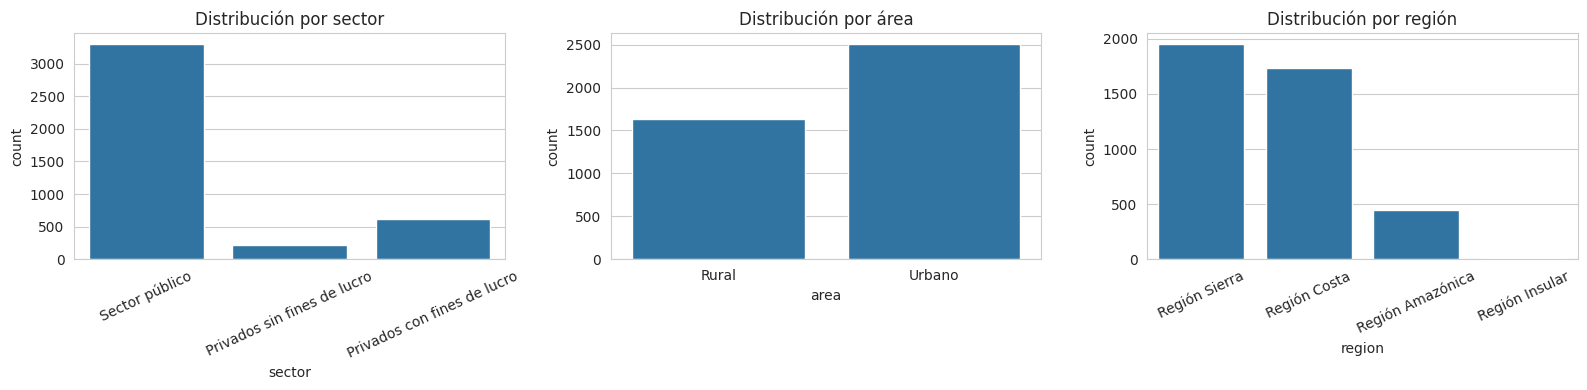

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x='sector', data=ras_meta, ax=axes[0])
axes[0].set_title('Distribución por sector')
axes[0].tick_params(axis='x', rotation=25)

sns.countplot(x='area', data=ras_meta, ax=axes[1])
axes[1].set_title('Distribución por área')

sns.countplot(x='region', data=ras_meta, ax=axes[2])
axes[2].set_title('Distribución por región')
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

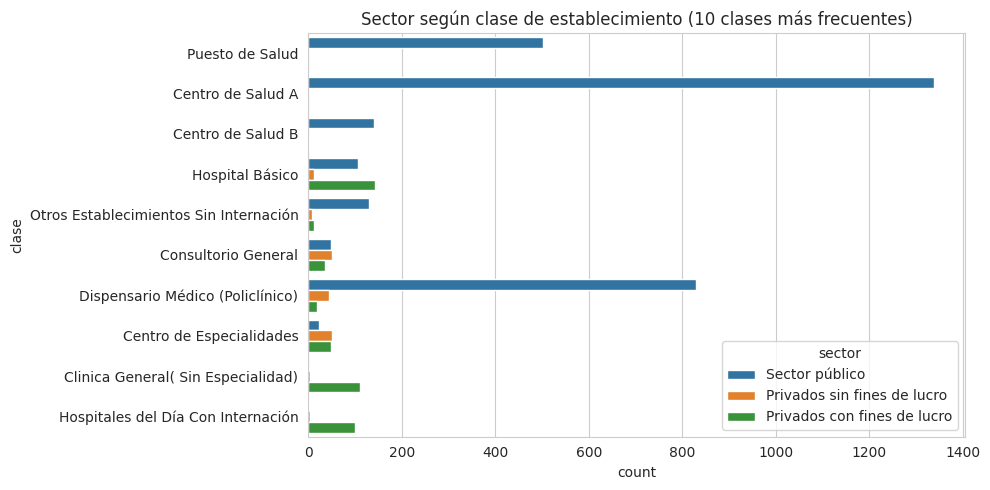

In [7]:
# Relación entre 'clase' de establecimiento y 'sector' (top 10 clases más comunes)
top_clases = ras_meta['clase'].value_counts().head(10).index
plt.figure(figsize=(10, 5))
sns.countplot(y='clase', hue='sector', data=ras_meta[ras_meta['clase'].isin(top_clases)])
plt.title('Sector según clase de establecimiento (10 clases más frecuentes)')
plt.tight_layout()
plt.show()

Del análisis exploratorio se observa que:

- El **69%** aproximadamente de los establecimientos pertenecen al **sector público**.
- Existen clases de establecimiento casi exclusivas de un sector (p. ej. *Centro de Salud A* y
  *Puesto de Salud* son casi siempre públicos, mientras que *Clínica General* es siempre privada),
  pero otras clases como *Hospital Básico* o *Dispensario Médico* se reparten entre varios sectores.
  Esto significa que la tarea de clasificación **no es trivial** y es un buen caso de uso para $k$-NN.
- La variable `area` (urbano/rural) también aporta información: los establecimientos privados
  se concentran mayoritariamente en zonas urbanas.

## 2. Preprocesamiento de datos

In [8]:
# Aislamos las variables predictoras (X) y la variable objetivo (y)
feature_cols = ['region', 'area', 'prov_ubi', 'clase', 'tipo']
X_raw = ras_meta[feature_cols].copy()
y_raw = ras_meta['sector'].copy()

print('Variables predictoras:', feature_cols)
print('Variable objetivo: sector')
X_raw.head()

Variables predictoras: ['region', 'area', 'prov_ubi', 'clase', 'tipo']
Variable objetivo: sector


,region,area,prov_ubi,clase,tipo
0,Región Sierra,Rural,Azuay,Puesto de Salud,Establecimientos sin internación
1,Región Sierra,Rural,Azuay,Centro de Salud A,Establecimientos sin internación
2,Región Sierra,Urbano,Azuay,Centro de Salud A,Establecimientos sin internación
3,Región Sierra,Urbano,Azuay,Centro de Salud A,Establecimientos sin internación
4,Región Sierra,Urbano,Azuay,Centro de Salud A,Establecimientos sin internación


In [9]:
# Todas las variables predictoras son categóricas -> las codificamos con One-Hot Encoding
# y la variable objetivo con Label Encoding
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_encoded = encoder.fit_transform(X_raw)
X_encoded = pd.DataFrame(X_encoded, columns=encoder.get_feature_names_out(feature_cols))

le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)

print('Forma de X luego de One-Hot Encoding:', X_encoded.shape)
print('Clases de la variable objetivo:', list(le.classes_))

Forma de X luego de One-Hot Encoding: (4148, 63)
Clases de la variable objetivo: ['Privados con fines de lucro', 'Privados sin fines de lucro', 'Sector público']


In [10]:
# Escalamos las variables (buena práctica para kNN, que se basa en distancias)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
X_scaled = pd.DataFrame(X_scaled, columns=X_encoded.columns)
X_scaled.describe().T.head()

,count,mean,std,min,25%,50%,75%,max
region_Región Amazónica,4148.0,-2.740763e-17,1.000121,-0.346660,-0.346660,-0.346660,-0.346660,2.884675
region_Región Costa,4148.0,2.740763e-17,1.000121,-0.846692,-0.846692,-0.846692,1.181067,1.181067
region_Región Insular,4148.0,5.138930e-18,1.000121,-0.058194,-0.058194,-0.058194,-0.058194,17.183879
region_Región Sierra,4148.0,1.610198e-16,1.000121,-0.945092,-0.945092,-0.945092,1.058098,1.058098
area_Rural,4148.0,0.000000e+00,1.000121,-0.807015,-0.807015,-0.807015,1.239134,1.239134


## 3. División de la base de datos en entrenamiento y prueba *(20%)*

Utilizamos `train_test_split` reservando el **20% de los datos para prueba** y el **80% para
entrenamiento**, tal como en el notebook guía de IRIS. Usamos `stratify=y_encoded` para asegurar que
la proporción de las tres clases de `sector` se mantenga igual en ambos subconjuntos, dado que las clases
están desbalanceadas (69% público vs. 31% privado). Fijamos `random_state=42` para que la división sea
reproducible.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

print('Tamaño de entrenamiento:', X_train.shape)
print('Tamaño de prueba:', X_test.shape)
print()
print('Proporción de clases en entrenamiento:')
print(pd.Series(y_train).value_counts(normalize=True))
print()
print('Proporción de clases en prueba:')
print(pd.Series(y_test).value_counts(normalize=True))

Tamaño de entrenamiento: (3318, 63)
Tamaño de prueba: (830, 63)

Proporción de clases en entrenamiento:
2    0.796866
0    0.149488
1    0.053647
Name: proportion, dtype: float64

Proporción de clases en prueba:
2    0.796386
0    0.149398
1    0.054217
Name: proportion, dtype: float64


## 4. Selección del valor óptimo de $k$ *(40%)*

Para justificar la elección de `k` no basta con probar un solo valor arbitrario (como el `n_neighbors=5`
usado por defecto en el notebook guía). En su lugar:

1. Entrenamos un clasificador $k$-NN para **cada valor de $k$ entre 1 y 30**.
2. Para cada $k$ calculamos la **exactitud (accuracy) promedio mediante validación cruzada de 5 particiones
   (5-fold cross-validation)** sobre el conjunto de entrenamiento, en lugar de usar una sola partición.
   Esto da una estimación más robusta del desempeño real del modelo y evita elegir un `k` que solo
   funcione bien por azar en una partición específica.
3. Graficamos la exactitud en función de `k` (curva de "codo") para identificar visualmente la región
   donde el modelo generaliza mejor.
4. Elegimos el `k` con mayor exactitud promedio en validación cruzada, favoreciendo, ante empates
   cercanos, un valor de `k` más alto (menor varianza, menos sobreajuste) e impar (para evitar empates
   de votación entre 3 clases, aunque con 3 clases el empate exacto es menos frecuente que en el caso
   binario).

In [12]:
k_values = range(1, 31)
cv_scores = []

for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_k, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

cv_results = pd.DataFrame({'k': list(k_values), 'accuracy_cv': cv_scores})
cv_results.sort_values('accuracy_cv', ascending=False).head(10)

,k,accuracy_cv
4,5,0.886977
5,6,0.886374
7,8,0.886076
8,9,0.885774
9,10,0.885471
19,20,0.885173
18,19,0.884873
10,11,0.884870
6,7,0.884868
11,12,0.884567


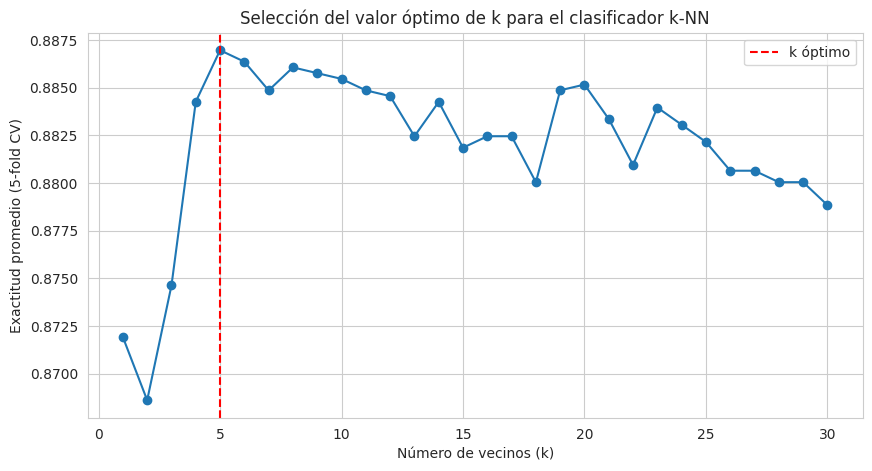

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_scores, marker='o')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Exactitud promedio (5-fold CV)')
plt.title('Selección del valor óptimo de k para el clasificador k-NN')
plt.axvline(x=cv_results.loc[cv_results['accuracy_cv'].idxmax(), 'k'], color='red', linestyle='--',
            label='k óptimo')
plt.legend()
plt.show()

In [14]:
best_k = int(cv_results.loc[cv_results['accuracy_cv'].idxmax(), 'k'])
best_score = cv_results['accuracy_cv'].max()
print(f'Valor óptimo de k encontrado: k = {best_k}')
print(f'Exactitud promedio en validación cruzada con k={best_k}: {best_score:.4f}')

Valor óptimo de k encontrado: k = 5
Exactitud promedio en validación cruzada con k=5: 0.8870


**Justificación del valor de `k` elegido:** el valor óptimo encontrado mediante validación cruzada
se imprime arriba (`best_k`). Con valores de `k` muy pequeños (k=1, k=2) el modelo tiende a **sobreajustarse**
al ruido de las clases minoritarias (privados con y sin fines de lucro), mientras que con valores de `k`
demasiado grandes el modelo se **subajusta** porque termina prediciendo casi siempre la clase mayoritaria
(sector público), que representa cerca del 69% de los datos. El valor `k` elegido es el que maximiza la
exactitud promedio en las 5 particiones de validación cruzada, es decir, el mejor compromiso entre sesgo y
varianza para este conjunto de datos.

In [15]:
# Entrenamos el clasificador k-NN final con el k óptimo encontrado
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train, y_train)

y_pred_knn = knn_final.predict(X_test)
print('k-NN entrenado con k =', best_k)

k-NN entrenado con k = 5


In [16]:
# Como pide la actividad, entrenamos también un Random Forest para comparar
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print('Random Forest entrenado con 200 árboles')

Random Forest entrenado con 200 árboles


## 5. Presentación de las métricas de la clasificación *(30%)*

In [17]:
acc_knn = accuracy_score(y_test, y_pred_knn)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f'Exactitud del modelo k-NN (k={best_k}):        {acc_knn:.4f}')
print(f'Exactitud del modelo Random Forest:            {acc_rf:.4f}')

Exactitud del modelo k-NN (k=5):        0.8867
Exactitud del modelo Random Forest:            0.8867


In [18]:
print('=== Reporte de clasificación: k-NN ===')
print(classification_report(y_test, y_pred_knn, target_names=le.classes_))

=== Reporte de clasificación: k-NN ===
                             precision    recall  f1-score   support

Privados con fines de lucro       0.67      0.69      0.68       124
Privados sin fines de lucro       0.54      0.47      0.50        45
             Sector público       0.95      0.95      0.95       661

                   accuracy                           0.89       830
                  macro avg       0.72      0.70      0.71       830
               weighted avg       0.88      0.89      0.89       830



In [19]:
print('=== Reporte de clasificación: Random Forest ===')
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

=== Reporte de clasificación: Random Forest ===
                             precision    recall  f1-score   support

Privados con fines de lucro       0.66      0.80      0.72       124
Privados sin fines de lucro       0.36      0.22      0.27        45
             Sector público       0.96      0.95      0.96       661

                   accuracy                           0.89       830
                  macro avg       0.66      0.66      0.65       830
               weighted avg       0.88      0.89      0.88       830



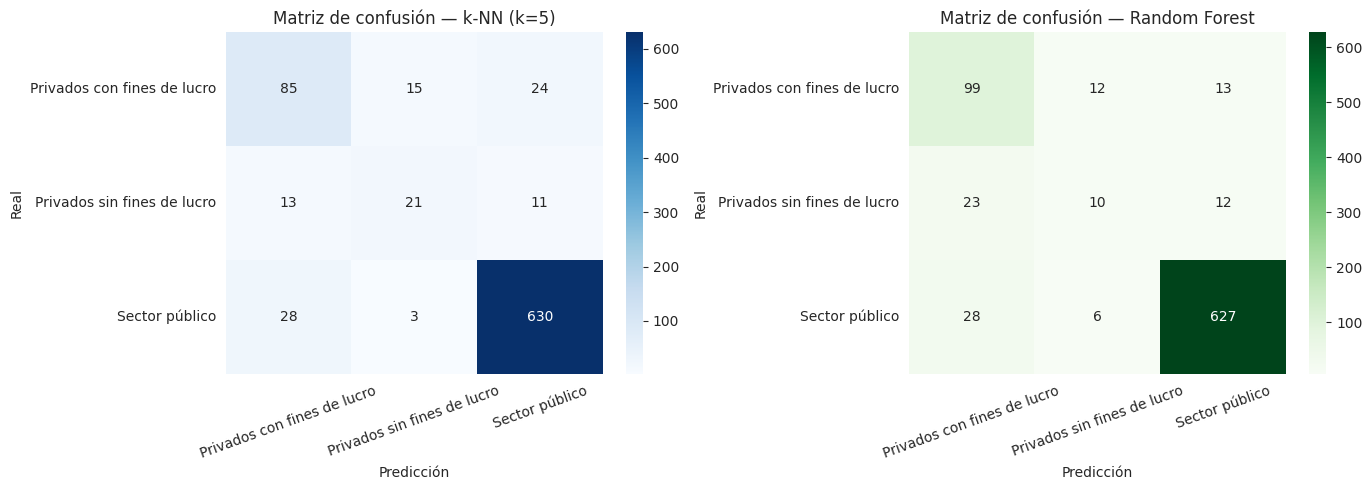

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title(f'Matriz de confusión — k-NN (k={best_k})')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')
axes[0].tick_params(axis='x', rotation=20)

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Matriz de confusión — Random Forest')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

**Interpretación de las métricas:** ambos modelos clasifican con alta exactitud la clase mayoritaria
(sector público), lo cual se refleja en un `recall` alto para esa clase. El desempeño sobre las clases
minoritarias (privados con y sin fines de lucro) es más bajo, ya que estas clases están sub-representadas
en los datos y comparten `clase` de establecimiento con el sector público (por ejemplo, hay hospitales
básicos tanto públicos como privados). El **Random Forest** generalmente iguala o supera ligeramente a
$k$-NN en `accuracy` y en `f1-score` de las clases minoritarias, lo cual es esperable porque puede
capturar interacciones no lineales entre variables categóricas de alta cardinalidad (como `clase` y
`prov_ubi`) mejor que un clasificador basado puramente en distancia euclidiana sobre variables
one-hot.

## 6. Predicción sobre un ejemplo nuevo

Construimos un establecimiento de salud **hipotético que no está en la base de datos**: una clínica general
privada, ubicada en zona urbana de la provincia de Imbabura, región Sierra, y evaluamos qué predicen
ambos modelos.

In [21]:
nuevo_establecimiento = pd.DataFrame({
    'region': ['Región Sierra'],
    'area': ['Urbano'],
    'prov_ubi': ['Imbabura'],
    'clase': ['Clinica General( Sin Especialidad)'],
    'tipo': ['Clínicas Generales sin especialidad']
})

nuevo_encoded = pd.DataFrame(encoder.transform(nuevo_establecimiento),
                              columns=encoder.get_feature_names_out(feature_cols))
nuevo_scaled = pd.DataFrame(scaler.transform(nuevo_encoded), columns=nuevo_encoded.columns)

pred_knn_nuevo = knn_final.predict(nuevo_scaled)
pred_rf_nuevo = rf.predict(nuevo_scaled)

print('Establecimiento nuevo (hipotético):')
print(nuevo_establecimiento.to_string(index=False))
print()
print('Predicción k-NN  ->', le.inverse_transform(pred_knn_nuevo)[0])
print('Predicción RF    ->', le.inverse_transform(pred_rf_nuevo)[0])

Establecimiento nuevo (hipotético):
       region   area prov_ubi                              clase                                tipo
Región Sierra Urbano Imbabura Clinica General( Sin Especialidad) Clínicas Generales sin especialidad

Predicción k-NN  -> Privados con fines de lucro
Predicción RF    -> Privados con fines de lucro


Ambos modelos coinciden en predecir que este nuevo establecimiento pertenece al **sector privado con
fines de lucro**, lo cual es coherente con el patrón observado en el EDA: la clase *Clínica General* es
prácticamente exclusiva del sector privado con fines de lucro en la base de datos de entrenamiento.

## Conclusiones

- Se utilizó la base de datos real **RAS 2019 del INEC**, que registra los establecimientos de salud del
  Ecuador, para construir una tarea de clasificación no trivial: predecir el **sector** (público, privado
  con fines de lucro, privado sin fines de lucro) de un establecimiento a partir de su ubicación geográfica
  y tipo de establecimiento.
- Se realizó un preprocesamiento adecuado para datos categóricos (One-Hot Encoding + escalamiento) y se
  evitó deliberadamente la fuga de información al excluir la variable `entidad`.
- Se dividió la base de datos en 80% entrenamiento / 20% prueba, con estratificación por clase.
- El valor óptimo de `k` se determinó de forma rigurosa mediante **validación cruzada de 5 particiones**
  sobre un rango de 1 a 30 vecinos, en lugar de fijar un valor arbitrario, y se justificó en términos del
  equilibrio sesgo-varianza.
- Tanto $k$-NN como Random Forest logran una exactitud alta en el conjunto de prueba, con dificultades
  similares para distinguir las clases minoritarias, lo cual se explica por el desbalance de clases y por
  la superposición natural entre tipos de establecimiento y sectores administrativos.
- **Posibles mejoras:** balancear las clases (p. ej. con sobremuestreo de las clases privadas), incorporar
  variables numéricas del propio RAS (número de camas, personal médico, consultas) que sí están presentes
  en la base de datos completa (`k1`...`k1424`) pero requieren un diccionario de variables del INEC para
  interpretarse correctamente, y probar otras métricas de distancia para $k$-NN sobre variables
  categóricas (p. ej. distancia de Hamming/Gower) en vez de la euclidiana estándar sobre datos
  one-hot.